# Predicting Customer Ride Cancellations: A Machine Learning Approach to Rideshare Marketplace Behavior

## Research question: Can we predict whether a customer will cancel a ride using trip, pricing, waiting-time, location, and customer/driver characteristics?

### Step 1 — Load and inspect the dataset

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load the dataset
df = pd.read_csv("ncr_ride_bookings.csv") #found this on Kaggle

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:") #lots of missingness for some variables
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

print("\nBooking status counts:")
display(df["Booking Status"].value_counts(dropna=False))

Dataset shape: (150000, 21)

Column names:
['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']

First five rows:


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI



Data types:


Date                                     str
Time                                     str
Booking ID                               str
Booking Status                           str
Customer ID                              str
Vehicle Type                             str
Pickup Location                          str
Drop Location                            str
Avg VTAT                             float64
Avg CTAT                             float64
Cancelled Rides by Customer          float64
Reason for cancelling by Customer        str
Cancelled Rides by Driver            float64
Driver Cancellation Reason               str
Incomplete Rides                     float64
Incomplete Rides Reason                  str
Booking Value                        float64
Ride Distance                        float64
Driver Ratings                       float64
Customer Rating                      float64
Payment Method                           str
dtype: object


Missing values:


,missing_count
Incomplete Rides Reason,141000
Incomplete Rides,141000
Cancelled Rides by Customer,139500
Reason for cancelling by Customer,139500
Driver Cancellation Reason,123000
Cancelled Rides by Driver,123000
Customer Rating,57000
Driver Ratings,57000
Ride Distance,48000
Booking Value,48000



Booking status counts:


Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

<Axes: >

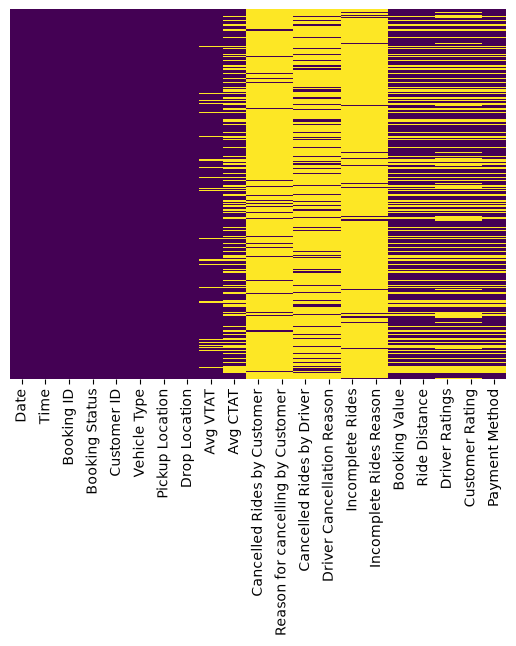

In [69]:
sns.heatmap(df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

### Step 2 — Define the analytic sample and outcome
My primary outcome is:
- 1 = Cancelled by Customer
- 0 = Completed
I will not treat a driver cancellation or a booking with no driver as a customer non-cancellation. Those are different marketplace outcomes.


In [62]:
#inspect the outcome
print(df["Booking Status"].unique())
print(df["Booking Status"].value_counts(dropna=False))

<ArrowStringArray>
[      'No Driver Found',            'Incomplete',             'Completed',
   'Cancelled by Driver', 'Cancelled by Customer']
Length: 5, dtype: str
Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64


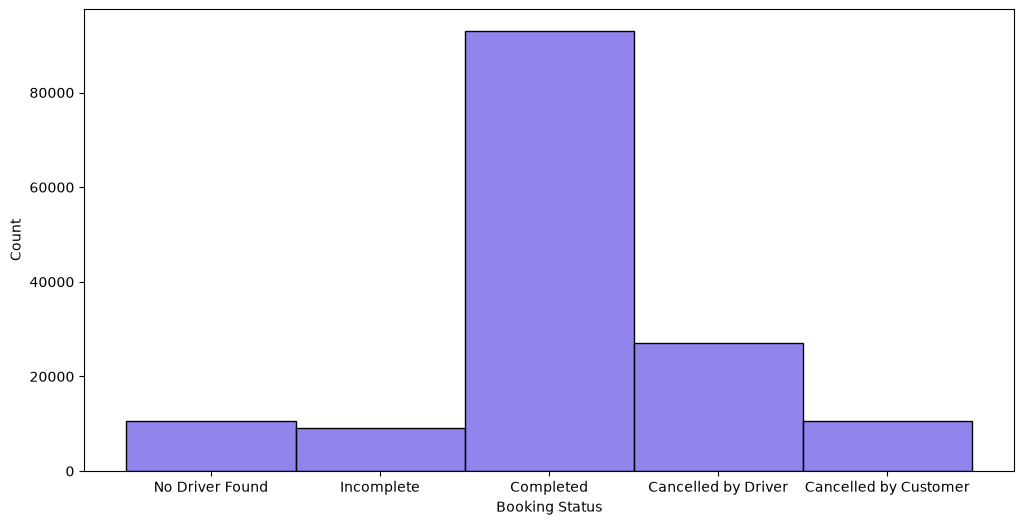

In [63]:
plt.figure(figsize=(12,6))
sns.histplot(df['Booking Status'],color='#6C5CE7')
plt.show()

In [64]:
# Keep only the two primary-analysis groups
analysis_df = df[
    df["Booking Status"].isin(["Cancelled by Customer", "Completed"])
].copy()

# Create the binary outcome
analysis_df["customer_cancelled"] = (
    analysis_df["Booking Status"] == "Cancelled by Customer"
).astype(int)

print(analysis_df["customer_cancelled"].value_counts(dropna=False))
print("Analytic sample size:", len(analysis_df))

customer_cancelled
0    93000
1    10500
Name: count, dtype: int64
Analytic sample size: 103500


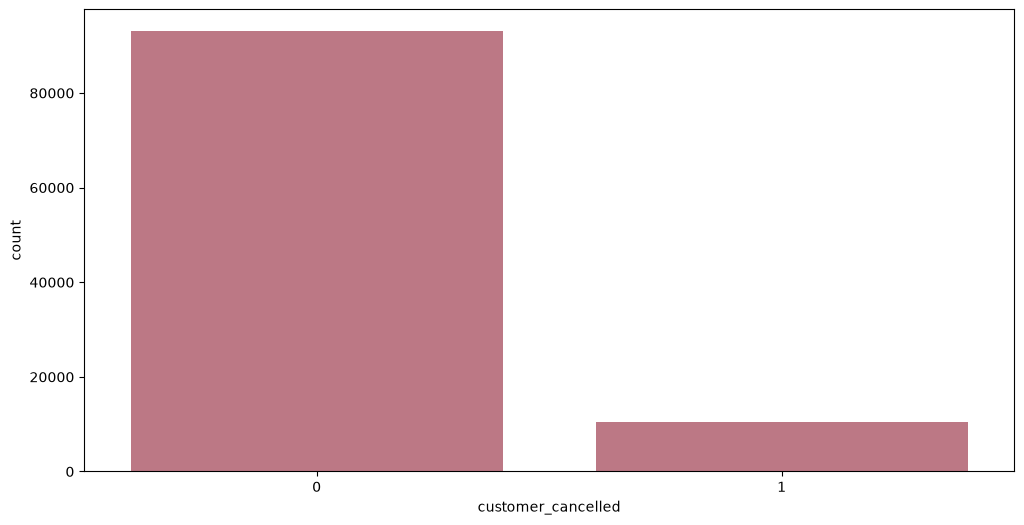

In [65]:
#plot the new outcome variable 
plt.figure(figsize=(12,6))
sns.countplot(
    data=analysis_df,
    x="customer_cancelled",
    color="#C76D7E"
)
plt.show()


## Step 3 — Audit target leakage and predictor availability

The fields below should not be model predictors because they directly reveal the outcome or are usually observed after the ride. IDs are also excluded as direct predictors.

`Avg VTAT`, `Avg CTAT`, and `Booking Value` require a timing check. In this first conservative model, they are excluded until we can verify that they were available when the prediction would be made...

In [66]:
leakage_or_exclusion_cols = [  # predictors not to use because they are post-outcome
    "Booking Status",
    "Cancelled Rides by Customer",
    "Reason for cancelling by Customer",
    "Cancelled Rides by Driver",
    "Driver Cancellation Reason",
    "Incomplete Rides",
    "Incomplete Rides Reason",
    "Customer Rating",
    "Driver Ratings",
    "Booking ID", #identifier
    "Customer ID",#identifier
    "Payment Method" #Not available before outcome
]

candidate_predictors = [
    "Vehicle Type", "Pickup Location", "Drop Location",
    "Ride Distance", "Booking Value", "Avg VTAT", "Avg CTAT",
     "Date", "Time"
]

print("Exclusion columns present:",
      [c for c in leakage_or_exclusion_cols if c in analysis_df.columns])

print("Candidate columns present:",
      [c for c in candidate_predictors if c in analysis_df.columns])


# Numeric variables
numeric_cols = [
    "Avg VTAT",
    "Avg CTAT",
    "Booking Value",
    "Ride Distance"
]

for col in numeric_cols:
    if col in analysis_df.columns:
        print(f"\n{col} by outcome:")
        display(
            analysis_df.groupby("Booking Status", dropna=False)[col]
            .agg(["count", "mean", "median"])
        )


print(f"\n{"Avg VTAT"} by outcome:")
display(
            analysis_df.groupby("Booking Status", dropna=False)["Avg VTAT"]
            .agg(["count", "mean", "median"])
        )

Exclusion columns present: ['Booking Status', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Customer Rating', 'Driver Ratings', 'Booking ID', 'Customer ID', 'Payment Method']
Candidate columns present: ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Ride Distance', 'Booking Value', 'Avg VTAT', 'Avg CTAT', 'Date', 'Time']

Avg VTAT by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,10500,12.512381,12.6
Completed,93000,8.511878,8.5



Avg CTAT by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,0,NaN,NaN
Completed,93000,30.034772,30.0



Booking Value by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,0,NaN,NaN
Completed,93000,508.178215,414.0



Ride Distance by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,0,NaN,NaN
Completed,93000,26.000493,26.02



Avg VTAT by outcome:


,count,mean,median
Booking Status,,,
Cancelled by Customer,10500,12.512381,12.6
Completed,93000,8.511878,8.5


## Step 4 — Clean dates and time features

In [67]:
#combine date with time
analysis_df["Date"] = pd.to_datetime(analysis_df["Date"], errors="coerce")
print(analysis_df["Date"])
analysis_df["Time_parsed"] = pd.to_timedelta(analysis_df["Time"], errors="coerce")
analysis_df["booking_datetime"] = (
    analysis_df["Date"] + analysis_df["Time_parsed"]
)
print(analysis_df["booking_datetime"])

2        2024-08-23
3        2024-10-21
4        2024-09-16
5        2024-02-06
6        2024-06-17
            ...    
149995   2024-11-11
149996   2024-11-24
149997   2024-09-18
149998   2024-10-05
149999   2024-03-10
Name: Date, Length: 103500, dtype: datetime64[us]
2        2024-08-23 08:56:10
3        2024-10-21 17:17:25
4        2024-09-16 22:08:00
5        2024-02-06 09:44:56
6        2024-06-17 15:45:58
                 ...        
149995   2024-11-11 19:34:01
149996   2024-11-24 15:55:09
149997   2024-09-18 10:55:15
149998   2024-10-05 07:53:34
149999   2024-03-10 15:38:03
Name: booking_datetime, Length: 103500, dtype: datetime64[us]


<Axes: >

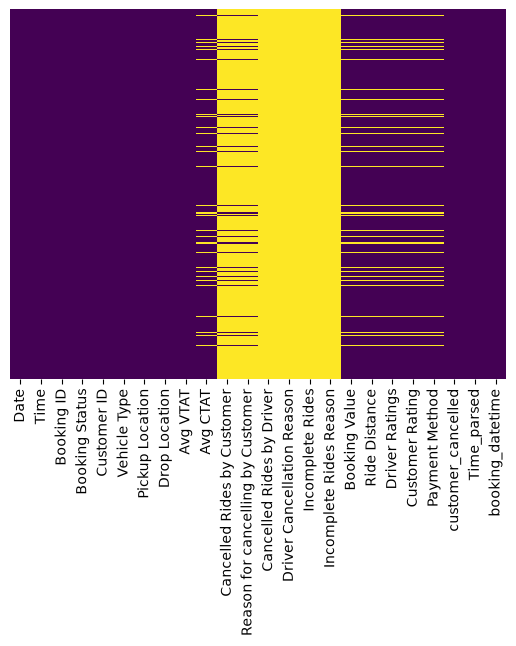

In [70]:
#checking missingness
sns.heatmap(analysis_df.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# 1. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=101
)

# 2. Identify numeric and categorical variables
num_cols = [c for c in numeric_features if c in X_train.columns]
cat_cols = [c for c in categorical_features if c in X_train.columns]

# 3. Prepare numeric variables
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 4. Prepare categorical variables
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 5. Combine the preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

# 6. Create logistic regression model
logmodel = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# 7. Fit the model
logmodel.fit(X_train, y_train)

# 8. Make predictions
predictions = logmodel.predict(X_test)

# 9. Make predictions on training data
predictions2 = logmodel.predict(X_train)

# 10. Look at the actual and predicted values
print(y_test.values)
print(y_train.values)

In [ ]:
predictions = logmodel.predict(X_test)

predictions2 = logmodel.predict(X_train)

print("Test predictions:")
print(predictions)

print("Training predictions:")
print(predictions2)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

print("Test accuracy:", accuracy_score(y_test, predictions))

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Build the SVM model
svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

# Predict cancellation probabilities
svm_prob = svm_model.predict_proba(X_test)[:, 1]

# Predict cancellation status using a 0.5 threshold
svm_pred = (svm_prob >= 0.5).astype(int)

# Evaluate model performance
svm_results = {
    "ROC_AUC": roc_auc_score(y_test, svm_prob),
    "Average_Precision": average_precision_score(y_test, svm_prob),
    "Precision": precision_score(y_test, svm_pred, zero_division=0),
    "Recall": recall_score(y_test, svm_pred, zero_division=0),
    "F1": f1_score(y_test, svm_pred, zero_division=0),
    "Accuracy": accuracy_score(y_test, svm_pred)
}

print("SVM Results")
print(classification_report(
    y_test,
    svm_pred,
    target_names=["Completed", "Cancelled by Customer"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, svm_pred))

print("\nSVM metrics:")
print(pd.Series(svm_results).round(3))